# Лабораторная работа № 3
## Свёрточные нейронные сети и перенос обучения для классификации изображений. Часть 2: перенос обучения, трёхклассовая классификация
### Вариант 7

Набор данных: PlantVillage, листья картофеля. Три класса: 0 - фитофтороз (`Potato___Late_blight`), 1 - здоровый лист (`Potato___healthy`), 2 - альтернариоз (`Potato___Early_blight`).

В этом ноутбуке выполняются задачи 1, 2, 7, 8 и 9 (для трёхклассовых моделей). Собственная CNN для бинарной задачи - в ноутбуке `nn-lab-3-binary.ipynb`. Оба ноутбука используют одинаковое разбиение на выборки.

## Цель работы

Получить практические навыки подготовки наборов изображений, построения и обучения свёрточных нейронных сетей (CNN), оценки качества моделей классификации, применения аугментации и регуляризации, а также использования предварительно обученных на ImageNet моделей с переносом обучения (transfer learning) и тонкой настройкой (fine-tuning).

## Задание

1. Изучить структуру выбранного набора изображений и сформировать три класса согласно индивидуальному варианту.
2. Подготовить данные: проверить изображения и метки, привести изображения к единому размеру и формату, разделить данные на обучающую, валидационную и тестовую выборки.
3. Построить и обучить собственную CNN для бинарной классификации классов 0 и 1.
4. Исследовать влияние архитектуры сети, числа фильтров, глубины сети, оптимизатора и Dropout на качество и устойчивость обучения.
5. Применить аугментацию только к обучающим данным и сравнить результаты с обучением без аугментации.
6. Выбрать и сохранить лучшую модель бинарной классификации.
7. Построить трёхклассовый классификатор на основе предварительно обученной на ImageNet свёрточной сети.
8. Сравнить два режима transfer learning: обучение классификационной "головы" при замороженной свёрточной основе и fine-tuning с частичной разморозкой основы.
9. Оценить модели на отложенной тестовой выборке, сравнить метрики, построить графики обучения и сформулировать выводы.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras нужно выбрать до импорта keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты и параметры эксперимента. Все константы собраны здесь, чтобы условия обучения были видны сразу.

In [2]:
import gc
import hashlib
import platform
import subprocess
import time
import warnings
from importlib.metadata import version

import seaborn as sns
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Файл весов хранит и состояние оптимизатора; при загрузке весов для предсказаний
# или для следующего этапа оно не нужно, и Keras предупреждает об этом. Скрываем
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

# Префикс имён файлов этого ноутбука в figures, results и models
NOTEBOOK_PREFIX = "transfer"

IMAGE_DIR = DATA_DIR / "plantvillage"
DATASET_URL = "https://www.kaggle.com/datasets/emmarex/plantdisease"

# Три класса варианта 7: номер класса равен позиции папки в списке
CLASS_FOLDERS = ["Potato___Late_blight", "Potato___healthy", "Potato___Early_blight"]
CLASS_NAMES = ["Фитофтороз", "Здоровый", "Альтернариоз"]

# Размер входа сети: рекомендуемые 224 x 224 пикселя
IMAGE_SIZE = 224

# Два снимка с корреляцией уменьшенных копий выше порога считаются снимками
# одного листа и попадают в одну выборку (порог обоснован в анализе данных)
NEAR_DUPLICATE_CORRELATION = 0.93

# Цвета графиков, одинаковые во всех рисунках
TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEST_COLOR = "#52514e"
CLASS_COLORS = ["#8c564b", "#1baf7a", "#d4a017"]

NUMBER_OF_CLASSES = len(CLASS_FOLDERS)
ALL_LABELS = list(range(NUMBER_OF_CLASSES))

# Режим A: основа заморожена, обучается только голова, шаг 10^-3 (как в задании)
HEAD_LEARNING_RATE = 0.001
MAX_EPOCHS_FROZEN = 40

# Режим B: fine-tuning последних слоёв основы с малым шагом 10^-5 и 10^-4
UNFROZEN_LAYERS = 30
FINE_TUNE_LEARNING_RATES = [0.00001, 0.0001]
MAX_EPOCHS_FINE = 30

BATCH_SIZE = 32
PATIENCE = 8

# Допуск при выборе модели по val loss: модели, которые отличаются меньше,
# считаются равными, и берётся та, у которой меньше обучаемых параметров
LOSS_TOLERANCE = 0.01

In [3]:
# Версии библиотек и оборудование: нужны, чтобы повторить эксперимент
for package in ["keras", "torch", "numpy", "pandas", "scikit-learn", "pillow", "matplotlib", "seaborn"]:
    print(f"{package}: {version(package)}")
print("Python:", platform.python_version())
print("Бэкенд Keras:", keras.backend.backend())
# Тензор Keras на бэкенде torch знает своё устройство: cuda:0 значит, что считает видеокарта
print("Устройство вычислений:", keras.ops.zeros(1).device)
gpu_query = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True)
print("Видеокарта:", gpu_query.stdout.strip() or "не найдена")
print("Процессор:", platform.processor(), "-", os.cpu_count(), "логических ядер")
print("ОС:", platform.platform())

keras: 3.15.1
torch: 2.12.1+cu126
numpy: 2.5.4
pandas: 3.1.0
scikit-learn: 1.9.1
pillow: 13.0.0
matplotlib: 3.11.2
seaborn: 0.13.2
Python: 3.12.10
Бэкенд Keras: torch
Устройство вычислений: cuda:0


Видеокарта: NVIDIA GeForce RTX 4070 Laptop GPU, 8188 MiB
Процессор: AMD64 Family 25 Model 116 Stepping 1, AuthenticAMD - 16 логических ядер
ОС: Windows-11-10.0.26200-SP0


**Результат:** Keras 3.15.1 на бэкенде torch 2.12.1 (CUDA 12.6), вычисления на видеокарте NVIDIA GeForce RTX 4070 Laptop GPU (8 ГБ), Python 3.12.10, Windows 11. Seed 42 фиксирован, но свёртки на видеокарте (cuDNN) выполняются не строго детерминированно, поэтому повторный запуск даёт близкие, но не побитово одинаковые числа.

## Описание набора данных

**Источник:** [PlantVillage Dataset](https://www.kaggle.com/datasets/emmarex/plantdisease), Kaggle (автор публикации emmarex). Изображения взяты из открытого репозитория PlantVillage ([spMohanty/PlantVillage-Dataset](https://github.com/spMohanty/PlantVillage-Dataset), папка raw/color), который собран проектом PlantVillage (Hughes, Salathe, 2015). Лицензия на Kaggle не указана, набор открыт для учебного использования.

**Описание с сайта (перевод):** "Набор изображений листьев больных растений и соответствующих меток. Набор взят из репозитория spMohanty на GitHub. Создан для системы распознавания болезней растений."

**Что это за данные.** Одна запись - это цветная фотография одного листа картофеля, снятая сверху на однородном сером фоне. Метка записи - папка, в которой лежит файл: она говорит, болен ли лист и какой болезнью. Модель по фотографии листа предсказывает его состояние. Такая модель нужна для ранней диагностики: фермер фотографирует лист телефоном и узнаёт о болезни раньше, чем она распространится по полю.

Классы варианта 7 (остальные 12 папок архива - томат и перец - не используются):

| Номер класса | Папка в архиве | Содержание | Признаки на листе |
|---|---|---|---|
| 0 | `Potato___Late_blight` | фитофтороз картофеля (Phytophthora infestans) | тёмные водянистые пятна без чёткой границы, часто от края листа |
| 1 | `Potato___healthy` | здоровый лист картофеля | равномерно зелёный лист без пятен |
| 2 | `Potato___Early_blight` | альтернариоз, ранняя сухая пятнистость (Alternaria solani) | коричневые сухие пятна с концентрическими кольцами и жёлтым ореолом |

Поля одной записи:

| Поле | Содержание | Значения по данным |
|---|---|---|
| изображение (файл `.JPG`) | фотография листа, 3 канала RGB | 256 x 256 пикселей, яркость каждого канала 0-255 |
| папка | название класса | 3 папки варианта, см. таблицу выше |
| имя файла | уникальный идентификатор и номер снимка (`RS_LB 4640`) | метка серии совпадает с папкой: `RS_LB`, `RS_HL`, `RS_Early.B` |

Размеры, режим RGB и диапазон значений проверяются ниже по самим файлам.

Составляем таблицу файлов трёх классов варианта. Если данных нет, ноутбук сообщает, что и откуда скачать.

In [4]:
# labs/data нет в git, поэтому при первом запуске набор нужно скачать самому
missing_folders = [folder for folder in CLASS_FOLDERS if not (IMAGE_DIR / folder).is_dir()]
if missing_folders:
    raise FileNotFoundError(
        f"Не найдены папки {missing_folders} в {IMAGE_DIR}. Скачайте набор {DATASET_URL} "
        "и скопируйте из папки PlantVillage архива три папки Potato___* в labs/data/plantvillage"
    )

# Таблица файлов: путь относительно IMAGE_DIR и номер класса по папке
file_records = []
for label, folder in enumerate(CLASS_FOLDERS):
    for path in sorted((IMAGE_DIR / folder).iterdir()):
        if path.is_file():
            file_records.append({"file": f"{folder}/{path.name}", "folder": folder, "label": label})
files = pd.DataFrame(file_records)

print("Всего файлов в трёх папках:", len(files))
print("Расширения файлов:", files["file"].str.rsplit(".", n=1).str[-1].value_counts().to_dict())
files.sample(8, random_state=SEED)

Всего файлов в трёх папках: 2152
Расширения файлов: {'JPG': 2152}


,file,folder,label
1505,Potato___Early_blight/5dbb2c15-fc42-4611-b590-...,Potato___Early_blight,2
1660,Potato___Early_blight/8636092c-9357-4b4c-9d2d-...,Potato___Early_blight,2
889,Potato___Late_blight/e2ce6696-9f6e-445c-a6c6-c...,Potato___Late_blight,0
306,Potato___Late_blight/50abdfe1-411f-4afe-8f78-1...,Potato___Late_blight,0
1771,Potato___Early_blight/a29ed5b2-153c-4f0e-a633-...,Potato___Early_blight,2
109,Potato___Late_blight/1d4acd15-f2b9-4a2e-87da-9...,Potato___Late_blight,0
1649,Potato___Early_blight/8435fd63-0136-44f9-8dd4-...,Potato___Early_blight,2
1655,Potato___Early_blight/853f6d7a-836c-4829-ba2c-...,Potato___Early_blight,2


## Анализ данных

### Повреждённые файлы, размеры и формат

Каждый файл открывается и полностью декодируется: так проверяется, что он не повреждён, и собираются размер и цветовой режим.

In [5]:
def inspect_image(relative_path):
    """Открывает файл, проверяет его целостность и возвращает размер, режим и MD5.

    verify() проверяет структуру файла, load() полностью декодирует пиксели и ловит
    обрезанные файлы. MD5 содержимого нужен для поиска точных дубликатов.
    """
    path = IMAGE_DIR / relative_path
    content = path.read_bytes()
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            return {"readable": True, "width": image.width, "height": image.height,
                    "mode": image.mode, "md5": hashlib.md5(content).hexdigest()}
    except Exception as error:
        print("Повреждённый файл:", relative_path, error)
        return {"readable": False, "width": 0, "height": 0, "mode": "", "md5": hashlib.md5(content).hexdigest()}


inspection = pd.DataFrame([inspect_image(relative_path) for relative_path in files["file"]])
files = pd.concat([files, inspection], axis=1)

print("Повреждённых файлов:", int((~files["readable"]).sum()))
print("Размеры (ширина x высота):", files.groupby(["width", "height"]).size().to_dict())
print("Цветовые режимы:", files["mode"].value_counts().to_dict())

Повреждённых файлов: 0
Размеры (ширина x высота): {(256, 256): 2152}
Цветовые режимы: {'RGB': 2152}


**Результат:** все 2152 файла читаются и полностью декодируются, повреждённых нет. Все изображения одного размера 256 x 256 и в режиме RGB (три канала), поэтому приведение к 224 x 224 x 3 одинаково для всех файлов.

### Количество изображений в каждом классе и баланс

,Класс,Папка,Название,Изображений,Доля
0,0,Potato___Late_blight,Фитофтороз,1000,0.4647
1,1,Potato___healthy,Здоровый,152,0.0706
2,2,Potato___Early_blight,Альтернариоз,1000,0.4647


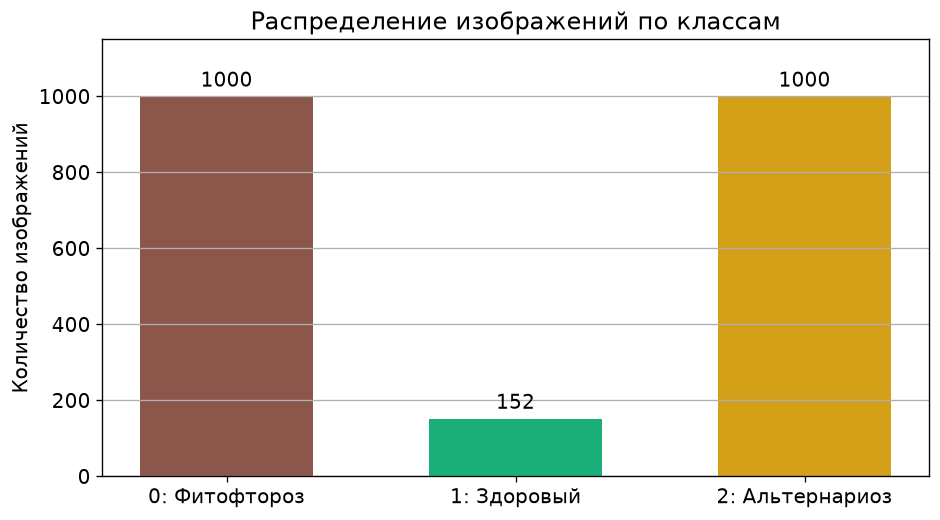

In [6]:
# Количество изображений в каждом классе
class_counts = files["label"].value_counts().sort_index()
count_table = pd.DataFrame({
    "Класс": range(len(CLASS_FOLDERS)),
    "Папка": CLASS_FOLDERS,
    "Название": CLASS_NAMES,
    "Изображений": class_counts.values,
    "Доля": (class_counts.values / len(files)).round(4),
})
display(count_table)

figure, axis = plt.subplots(figsize=(8, 4.5))
bars = axis.bar([f"{label}: {name}" for label, name in enumerate(CLASS_NAMES)], class_counts.values,
                color=CLASS_COLORS, width=0.6)
axis.bar_label(bars, padding=3)
axis.set_ylabel("Количество изображений")
axis.set_title("Распределение изображений по классам")
axis.set_ylim(0, class_counts.max() * 1.15)
axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-class-balance.png")
plt.show()

**Результат:** фитофтороз 1000 снимков (0,4647), здоровые листья 152 (0,0706), альтернариоз 1000 (0,4647). Классы 0 и 2 равны, а здоровых листьев в 6,6 раза меньше: класс 1 редкий, это нужно учитывать при обучении и оценке.

### Корректность меток

Сверяем метку серии съёмки из имени файла с папкой, по которой назначен класс.

In [7]:
# Имя файла содержит метку серии съёмки: RS_LB (late blight), RS_HL (healthy),
# RS_Early.B (early blight). Совпадение метки серии с папкой подтверждает, что
# снимки не перепутаны между папками
files["series_tag"] = files["file"].str.extract(r"___([A-Za-z_.]+?)\s*\d+\.\w+$", expand=False)
files["photo_number"] = files["file"].str.extract(r"(\d+)\.\w+$", expand=False).astype(int)
pd.crosstab(files["folder"], files["series_tag"])

series_tag,RS_Early.B,RS_HL,RS_LB
folder,,,
Potato___Early_blight,1000,0,0
Potato___Late_blight,0,0,1000
Potato___healthy,0,152,0


**Результат:** метка серии в имени файла во всех 2152 случаях совпадает с папкой: `RS_LB` только в папке фитофтороза, `RS_HL` только в папке здоровых, `RS_Early.B` только в папке альтернариоза. Перепутанных меток и посторонних файлов нет.

### Дубликаты и серии почти одинаковых снимков

Снимки одного листа в разных выборках дали бы утечку: модель на тесте узнала бы знакомый лист. Ищем точные дубликаты по MD5 и почти одинаковые снимки по корреляции уменьшенных копий 32 x 32. Пары выше порога `NEAR_DUPLICATE_CORRELATION` объединяются в группы, и группа целиком попадает в одну выборку.

Файлов с точными дубликатами: 0


,Файл 1,Файл 2,Корреляция
0,Potato___Early_blight/5aee3e9f-0469-42e7-8ae7-...,Potato___Early_blight/bc378ba0-533d-42db-a8b2-...,0.9475
1,Potato___Late_blight/8f634ae3-010a-4a08-aae9-2...,Potato___Late_blight/a74a91d8-1a9d-4fa8-bc4b-2...,0.9222
2,Potato___Late_blight/580e8c49-3b1c-46d2-b3f4-6...,Potato___Late_blight/e19d0007-3013-419d-a46a-0...,0.9077
3,Potato___Late_blight/580e8c49-3b1c-46d2-b3f4-6...,Potato___Late_blight/63dc685e-676c-4c9c-8f83-8...,0.9061
4,Potato___Late_blight/55fa97d3-71b6-4487-9757-f...,Potato___Late_blight/699bd8b5-3c57-48c8-be2b-c...,0.9050
5,Potato___Late_blight/0e7f0484-16eb-4183-b702-0...,Potato___Late_blight/e986907b-6948-4c72-93d3-2...,0.9045


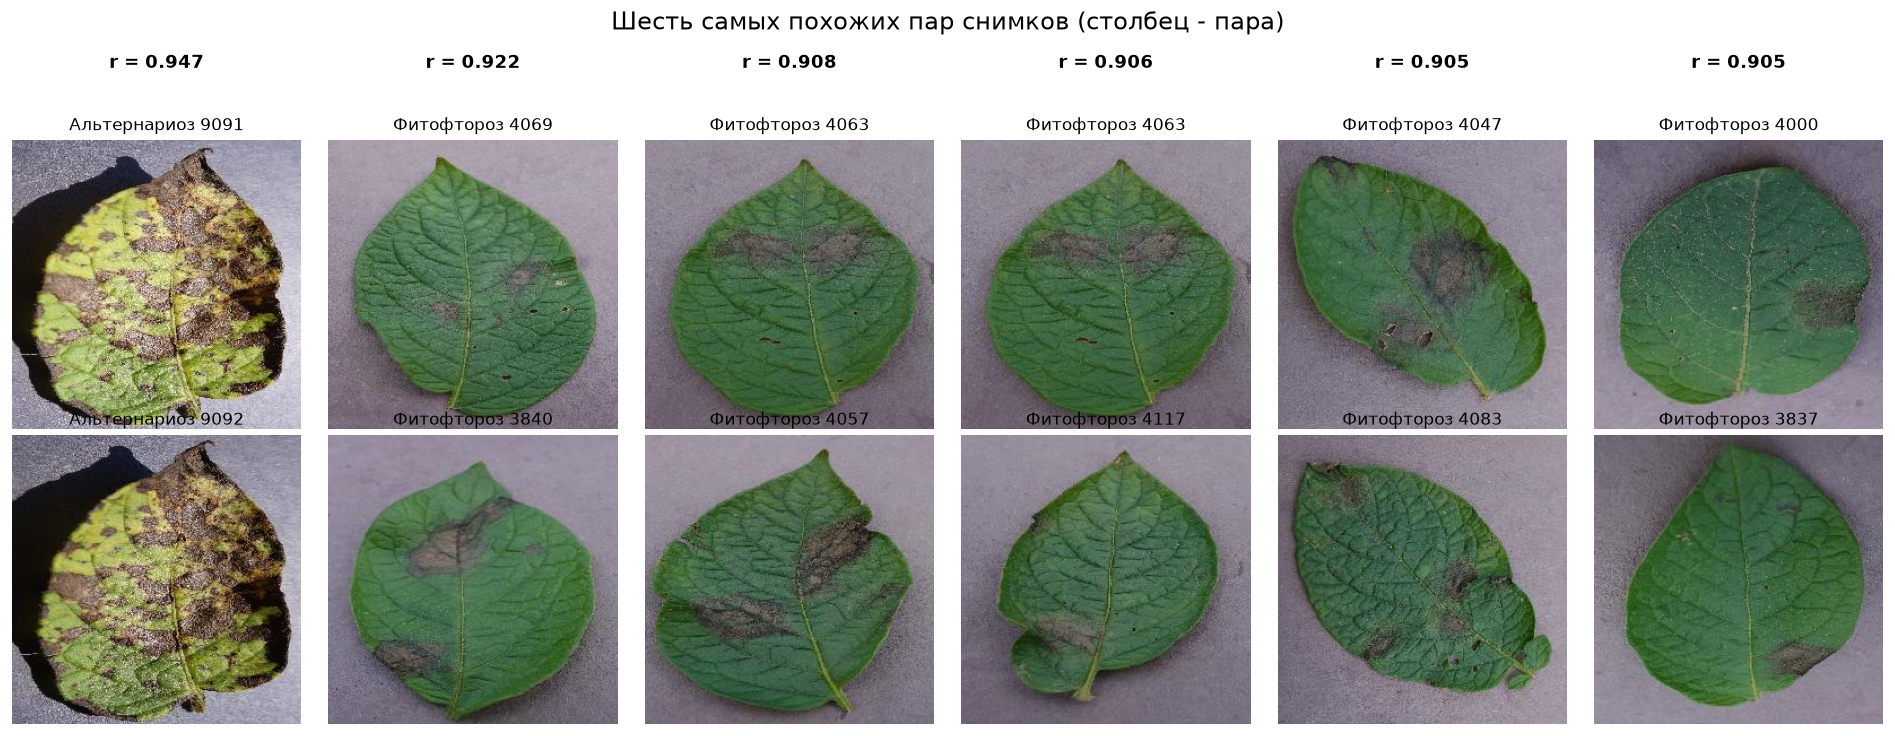

Пар с корреляцией >= 0.93: 1
Групп снимков: 2151 из 2152 файлов


In [8]:
# Точные дубликаты: одинаковое содержимое файла
exact_duplicate_files = int(files["md5"].duplicated(keep=False).sum())
print("Файлов с точными дубликатами:", exact_duplicate_files)


def thumbnail_vector(relative_path):
    """Уменьшает снимок до 32 x 32 в оттенках серого и нормирует его.

    Корреляция таких векторов близка к 1 только у почти одинаковых снимков:
    тот же лист, то же положение, другой кадр серии.
    """
    with Image.open(IMAGE_DIR / relative_path) as image:
        pixels = np.asarray(image.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel()
    return (pixels - pixels.mean()) / (pixels.std() + 1e-6)


thumbnails = np.stack([thumbnail_vector(relative_path) for relative_path in files["file"]])
correlation = thumbnails @ thumbnails.T / thumbnails.shape[1]
np.fill_diagonal(correlation, -1.0)

# Самые похожие пары снимков во всём наборе
upper_i, upper_j = np.triu_indices(len(files), k=1)
pair_values = correlation[upper_i, upper_j]
top_pairs = np.argsort(-pair_values)[:6]
similar_pairs = pd.DataFrame({
    "Файл 1": files["file"].to_numpy()[upper_i[top_pairs]],
    "Файл 2": files["file"].to_numpy()[upper_j[top_pairs]],
    "Корреляция": pair_values[top_pairs].round(4),
})
display(similar_pairs)

figure, axes = plt.subplots(2, 6, figsize=(16, 6))
for column, pair_index in enumerate(top_pairs):
    for row, file_index in enumerate((upper_i[pair_index], upper_j[pair_index])):
        with Image.open(IMAGE_DIR / files.loc[file_index, "file"]) as image:
            axes[row, column].imshow(image)
        axes[row, column].set_title(f"{CLASS_NAMES[files.loc[file_index, 'label']]} {files.loc[file_index, 'photo_number']}",
                                    fontsize=10)
        axes[row, column].axis("off")
    axes[0, column].text(0.5, 1.25, f"r = {pair_values[pair_index]:.3f}", transform=axes[0, column].transAxes,
                         ha="center", fontsize=11, fontweight="bold")
figure.suptitle("Шесть самых похожих пар снимков (столбец - пара)", y=1.02)
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-similar-pairs.png", bbox_inches="tight")
plt.show()

# Группы связанных снимков: пары выше порога объединяются в одну группу
near_pairs = np.argwhere(np.triu(correlation >= NEAR_DUPLICATE_CORRELATION))
group_of_file = np.arange(len(files))
for first, second in near_pairs:
    group_of_file[group_of_file == group_of_file[second]] = group_of_file[first]
files["group"] = group_of_file
print(f"Пар с корреляцией >= {NEAR_DUPLICATE_CORRELATION}:", len(near_pairs))
print("Групп снимков:", files["group"].nunique(), "из", len(files), "файлов")

**Результат:** точных дубликатов нет. Самая похожая пара (корреляция 0,9475) - это два кадра одного листа с альтернариозом, снимки 9091 и 9092 с соседними номерами: на рисунке это первый столбец. Следующая пара (0,9222) и все остальные - уже разные листья похожей формы на одинаковом фоне. Поэтому порог 0,93 отделяет снимки одного листа от просто похожих. Найдена одна такая пара, она объединена в группу: 2151 группа на 2152 файла.

### Примеры изображений

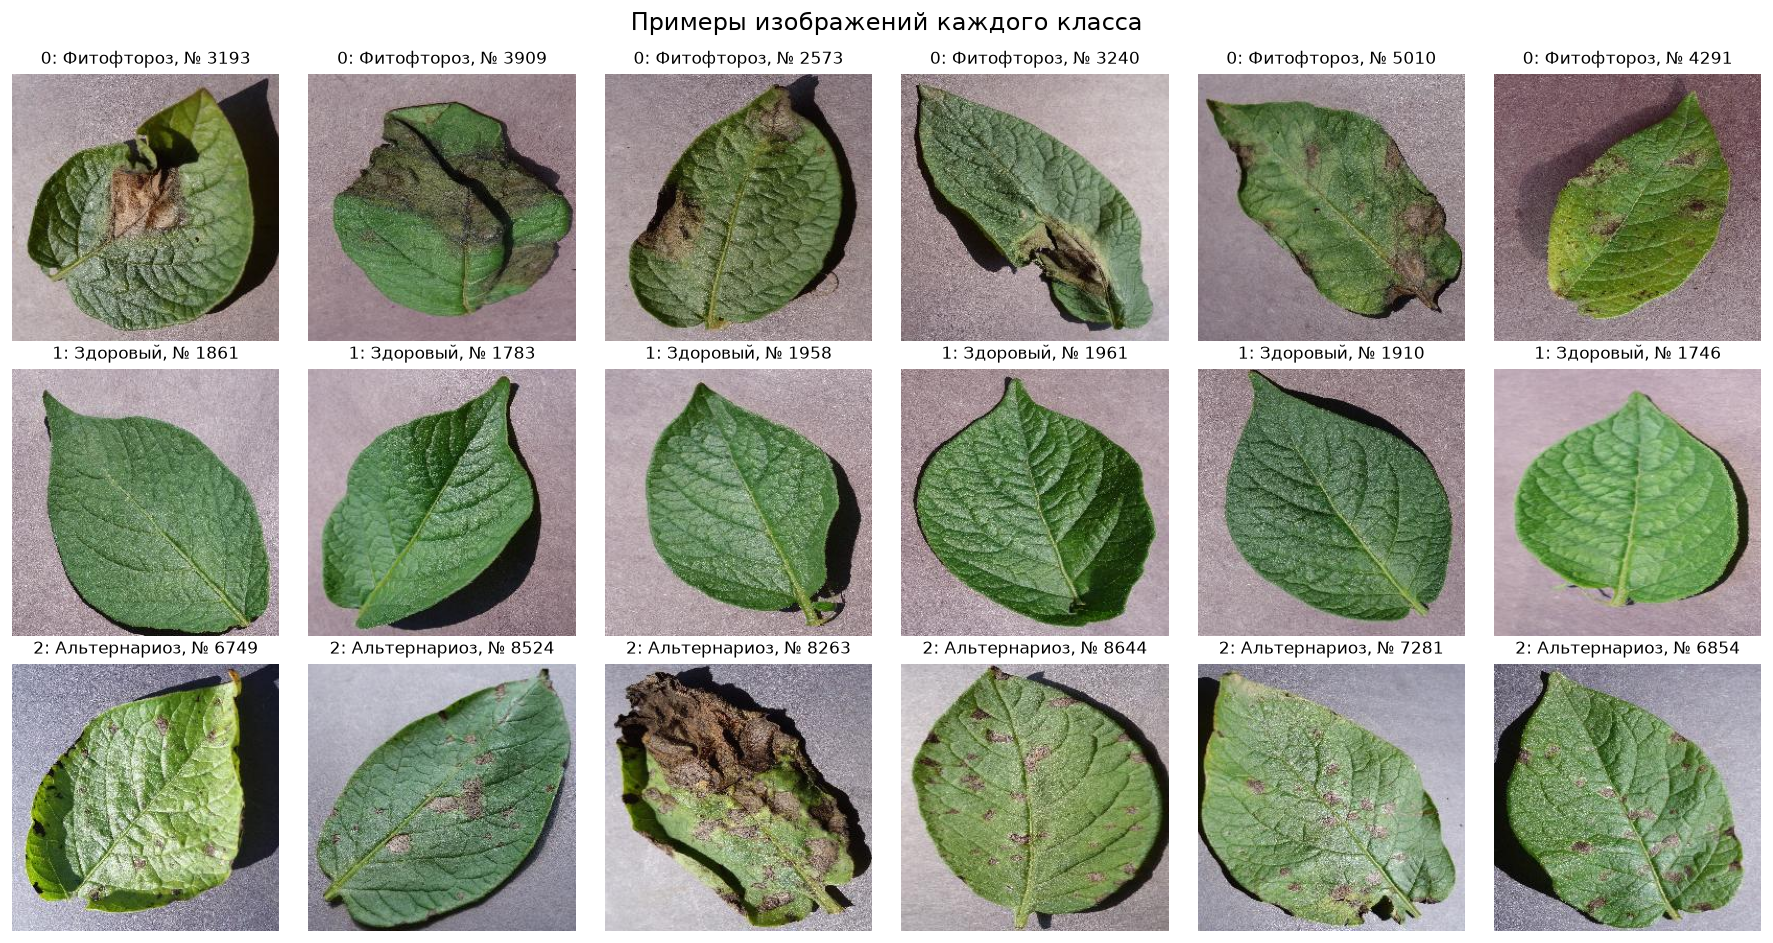

In [9]:
# Шесть случайных примеров каждого класса с подписями
examples_per_class = 6
figure, axes = plt.subplots(len(CLASS_FOLDERS), examples_per_class, figsize=(15, 8))
for label, name in enumerate(CLASS_NAMES):
    sample = files[files["label"] == label].sample(examples_per_class, random_state=SEED)
    for column, (_, record) in enumerate(sample.iterrows()):
        with Image.open(IMAGE_DIR / record["file"]) as image:
            axes[label, column].imshow(image)
        axes[label, column].set_title(f"{label}: {name}, № {record['photo_number']}", fontsize=10)
        axes[label, column].axis("off")
figure.suptitle("Примеры изображений каждого класса")
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-examples.png")
plt.show()

**Результат:** внутри класса снимки различаются ориентацией листа, размером, освещением и числом пятен. Фон у всех один (серый, снято в лаборатории), что упрощает задачу, но означает, что на полевых фото качество может быть ниже. Здоровые листья равномерно зелёные. Оба заболевания дают бурые пятна, поэтому фитофтороз и альтернариоз похожи друг на друга больше, чем на здоровый лист: у альтернариоза пятна сухие, с кольцами и желтизной вокруг, у фитофтороза тёмные, расплывчатые, часто от края.

## Подготовка данных

### Разбиение на выборки

Разбиение 70 / 15 / 15 со стратификацией по классу, `random_state=SEED`, по группам связанных снимков. Код разбиения тот же, что в ноутбуке бинарной задачи, поэтому тестовые снимки классов 0 и 1 совпадают. Списки файлов сохраняются в `results`.

In [10]:
# Каждая группа связанных снимков должна целиком попасть в одну выборку
assert files.groupby("group")["label"].nunique().max() == 1
groups = files.groupby("group", as_index=False)["label"].first()

# Первый шаг: 70% групп в train, 30% во временную часть; стратификация по классу
train_groups, rest_groups = train_test_split(groups, test_size=0.30, stratify=groups["label"],
                                             random_state=SEED)
# Второй шаг: временная часть делится пополам на validation и test
val_groups, test_groups = train_test_split(rest_groups, test_size=0.50, stratify=rest_groups["label"],
                                           random_state=SEED)

split_of_group = {**dict.fromkeys(train_groups["group"], "train"),
                  **dict.fromkeys(val_groups["group"], "validation"),
                  **dict.fromkeys(test_groups["group"], "test")}
files["split"] = files["group"].map(split_of_group)
SPLIT_ORDER = ["train", "validation", "test"]

# Проверка: группы не пересекаются между выборками
assert files.groupby("group")["split"].nunique().max() == 1


def split_distribution(frame, labels):
    """Таблица: число изображений каждого класса и доля положительного класса в выборках."""
    table = pd.crosstab(frame["split"], frame["label"]).reindex(index=SPLIT_ORDER, columns=labels)
    table.columns = [f"{label}: {CLASS_NAMES[label]}" for label in labels]
    table["Всего"] = table.sum(axis=1)
    for label in labels:
        table[f"Доля {label}"] = (table[f"{label}: {CLASS_NAMES[label]}"] / table["Всего"]).round(4)
    return table


display(split_distribution(files, ALL_LABELS))
files[["file", "label", "split"]].to_csv(RESULTS_DIR / "transfer-split.csv", index=False, encoding="utf-8")

,0: Фитофтороз,1: Здоровый,2: Альтернариоз,Всего,Доля 0,Доля 1,Доля 2
split,,,,,,,
train,700,106,700,1506,0.4648,0.0704,0.4648
validation,150,23,150,323,0.4644,0.0712,0.4644
test,150,23,150,323,0.4644,0.0712,0.4644


**Результат:** train 1506, validation 323, test 323 снимка. В каждой выборке фитофтороз и альтернариоз по 0,46, здоровые около 0,07 (106 / 23 / 23 снимка): стратификация сохранила доли классов. Пара снимков одного листа целиком в одной выборке. Тестовые снимки классов 0 и 1 те же, что в бинарной задаче. Списки файлов - `results/transfer-split.csv`.

### Единый размер, формат и нормализация для MobileNetV2

Изображения приводятся к 224 x 224 x 3 (RGB): это размер входа, на котором MobileNetV2 обучалась на ImageNet. Нормализация - только функция `preprocess_input` этой архитектуры: она переводит пиксели 0-255 в диапазон [-1; 1], как при предобучении. Деление на 255 здесь не применяется: две нормализации подряд дали бы сети входы не того масштаба, к которому привыкли её фильтры.

In [11]:
def load_images(relative_paths):
    """Читает изображения и приводит их к единому формату: RGB, IMAGE_SIZE x IMAGE_SIZE, uint8.

    convert("RGB") гарантирует три канала даже для серых или RGBA-файлов,
    resize с билинейной интерполяцией уменьшает 256 x 256 до 224 x 224.
    """
    images = np.empty((len(relative_paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for index, relative_path in enumerate(relative_paths):
        with Image.open(IMAGE_DIR / relative_path) as image:
            images[index] = np.asarray(image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR))
    return images


def load_split(split_name):
    """Возвращает X (float32 после preprocess_input, [-1; 1]) и y выбранной выборки."""
    part = files[files["split"] == split_name]
    images = load_images(part["file"].tolist()).astype("float32")
    return keras.applications.mobilenet_v2.preprocess_input(images), part["label"].to_numpy()


X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

for split_name, images, labels in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{split_name}: X {images.shape} {images.dtype}, диапазон [{images.min():.1f}; {images.max():.1f}], "
          f"y {np.bincount(labels).tolist()}")

train: X (1506, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [700, 106, 700]
validation: X (323, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [150, 23, 150]
test: X (323, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [150, 23, 150]


**Результат:** train 1506, validation и test по 323 изображения 224 x 224 x 3, после `preprocess_input` значения в диапазоне [-1; 1], как при обучении MobileNetV2 на ImageNet.

### Веса классов

Здоровых листьев всего 7% набора. Чтобы сеть не игнорировала редкий класс, ошибкам на нём даём больший вес. Веса считаются по обучающей выборке функцией `compute_class_weight("balanced")`:

$$ w_c = \frac{n}{K \cdot n_c} $$

где $n$ - число обучающих изображений, $K = 3$, $n_c$ - число изображений класса $c$. Validation и test не изменяются.

In [12]:
class_weight_values = compute_class_weight("balanced", classes=np.array(ALL_LABELS), y=y_train)
CLASS_WEIGHT = {label: float(weight) for label, weight in zip(ALL_LABELS, class_weight_values)}

class_weight_table = pd.DataFrame({
    "Класс": [f"{label}: {CLASS_NAMES[label]}" for label in ALL_LABELS],
    "Изображений в train": [int((y_train == label).sum()) for label in ALL_LABELS],
    "Вес": [round(CLASS_WEIGHT[label], 4) for label in ALL_LABELS],
})
class_weight_table["Вес x число"] = (class_weight_table["Изображений в train"] * class_weight_table["Вес"]).round(1)
class_weight_table.to_csv(RESULTS_DIR / "transfer-class-weights.csv", index=False, encoding="utf-8")
class_weight_table

,Класс,Изображений в train,Вес,Вес x число
0,0: Фитофтороз,700,0.7171,502.0
1,1: Здоровый,106,4.7358,502.0
2,2: Альтернариоз,700,0.7171,502.0


**Результат:** вес фитофтороза и альтернариоза 0,7171, вес здорового листа 4,7358. Произведение веса на число снимков у всех классов 502: каждый класс вносит в функцию потерь одинаковый вклад.

## Базовая модель

Метрики трёхклассовой задачи:

- Precision, Recall и F1 для каждого класса и их macro-среднее (простое среднее по классам, каждый класс одинаково важен):

$$ macro = \frac{1}{K}\sum_{k=1}^{K} m_k $$

- Balanced Accuracy - среднее Recall по классам;
- ROC-AUC по схеме One-vs-Rest: каждый класс против остальных, затем macro-среднее.

`Dummy` всегда называет самый частый класс. Это нижняя граница качества.

In [13]:
def evaluate_multiclass(y_true, class_probabilities):
    """Сводные метрики трёхклассовой модели по вероятностям классов."""
    predicted = class_probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, predicted, labels=ALL_LABELS,
                                                               average="macro", zero_division=0)
    return {
        "Accuracy": round(accuracy_score(y_true, predicted), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_true, predicted), 4),
        "Macro Precision": round(precision, 4),
        "Macro Recall": round(recall, 4),
        "Macro F1": round(f1, 4),
        "Macro ROC-AUC": round(roc_auc_score(y_true, class_probabilities, multi_class="ovr",
                                             average="macro", labels=ALL_LABELS), 4),
    }


def per_class_table(y_true, class_probabilities):
    """Precision, Recall, F1 и ROC-AUC (OvR) по каждому классу и macro-среднее."""
    predicted = class_probabilities.argmax(axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(y_true, predicted, labels=ALL_LABELS,
                                                                     zero_division=0)
    auc = [roc_auc_score(y_true == label, class_probabilities[:, label]) for label in ALL_LABELS]
    table = pd.DataFrame({"Precision": precision, "Recall": recall, "F1": f1, "ROC-AUC": auc, "Объектов": support},
                         index=[f"{label}: {CLASS_NAMES[label]}" for label in ALL_LABELS])
    table.loc["macro avg"] = [precision.mean(), recall.mean(), f1.mean(), np.mean(auc), support.sum()]
    table["Объектов"] = table["Объектов"].astype(int)
    return table.round(4)


dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
dummy_val_probabilities = dummy.predict_proba(np.zeros((len(y_val), 1)))
print("Dummy, validation:", evaluate_multiclass(y_val, dummy_val_probabilities))

Dummy, validation: {'Accuracy': 0.4644, 'Balanced Accuracy': 0.3333, 'Macro Precision': 0.1548, 'Macro Recall': 0.3333, 'Macro F1': 0.2114, 'Macro ROC-AUC': 0.5}


**Результат:** `Dummy` на validation: Accuracy 0,4644, Balanced Accuracy 0,3333, Macro F1 0,2114, Macro ROC-AUC 0,5. Это уровень угадывания для трёх классов.

## Эксперименты

### Выбранная архитектура: MobileNetV2

MobileNetV2 (Sandler и др., 2018) - сеть для мобильных устройств, предобученная на ImageNet (1,2 млн изображений, 1000 классов). Её основной блок - инвертированный остаточный блок: свёртка 1 x 1 расширяет число каналов, depthwise-свёртка 3 x 3 обрабатывает каждый канал отдельно, свёртка 1 x 1 снова сужает каналы, а остаточная связь складывает вход и выход блока. Активация - ReLU6. Свёрточная основа (без верхних слоёв ImageNet) имеет 154 слоя и около 2,26 млн параметров и для входа 224 x 224 выдаёт карту признаков 7 x 7 x 1280. Выбрана потому, что задание рекомендует её для ограниченных ресурсов: обучение идёт быстро на видеокарте 8 ГБ.

Классификационная голова по заданию: GlobalAveragePooling2D -> Dropout -> Dense(3, softmax), функция потерь `sparse_categorical_crossentropy` (метки - целые числа 0, 1, 2).

Основа вызывается с `training=False`: слои BatchNormalization всегда работают в режиме вывода со статистиками ImageNet. Иначе при fine-tuning маленькие батчи по 32 снимка сдвигали бы эти статистики и портили предобученные признаки.

Условия обучения для обоих режимов: batch 32, веса классов, `EarlyStopping` по `val_loss` с `restore_best_weights=True` и patience 8 (val loss на 323 снимках колеблется, 8 эпох переживают короткий всплеск), `ModelCheckpoint` сохраняет лучшие веса в `models`. Выбор - по val loss с допуском `LOSS_TOLERANCE`.

In [14]:
def build_transfer_model(dropout_rate, seed=SEED):
    """Собирает MobileNetV2 с ImageNet-весами и новой головой на 3 класса.

    Возвращает модель и её свёрточную основу (base), чтобы потом менять trainable.
    Основа создаётся замороженной: режим A.
    """
    keras.utils.set_random_seed(seed)
    base = keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                          input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    base.trainable = False

    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    # training=False: BatchNormalization основы всегда в режиме вывода
    features = base(inputs, training=False)
    features = keras.layers.GlobalAveragePooling2D()(features)
    if dropout_rate > 0:
        features = keras.layers.Dropout(dropout_rate)(features)
    outputs = keras.layers.Dense(NUMBER_OF_CLASSES, activation="softmax")(features)
    return keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base


def compile_model(model, learning_rate):
    """Компиляция нужна заново после каждого изменения trainable."""
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])


def unfreeze_top(base, number_of_layers):
    """Размораживает последние number_of_layers слоёв основы, кроме BatchNormalization.

    Нижние слои (общие признаки: границы, текстуры) остаются замороженными.
    BatchNormalization не обучаем: его статистики ImageNet нужно сохранить.
    """
    base.trainable = True
    for layer in base.layers[:-number_of_layers]:
        layer.trainable = False
    for layer in base.layers[-number_of_layers:]:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False


def count_trainable(model):
    """Число обучаемых параметров модели."""
    return int(sum(np.prod(weight.shape) for weight in model.trainable_weights))


def describe_architecture(model, base):
    """summary() модели, состав основы и функции активации головы."""
    model.summary()
    activation_counts = pd.Series([type(layer).__name__ for layer in base.layers]).value_counts()
    print("Слоёв в основе MobileNetV2:", len(base.layers))
    print("Типы слоёв основы:", activation_counts.to_dict())
    relu6_layers = [layer for layer in base.layers if isinstance(layer, keras.layers.ReLU)]
    print("Активация основы: ReLU с max_value =", relu6_layers[0].max_value, "(ReLU6) в", len(relu6_layers), "слоях")
    head = [f"{layer.name}: {layer.activation.__name__}" for layer in model.layers
            if getattr(layer, "activation", None) is not None]
    print("Активации головы:", ", ".join(head))
    print("Обучаемых параметров:", count_trainable(model), "из", model.count_params())


def model_file(model_name):
    """Путь к файлу лучших весов модели."""
    return MODELS_DIR / f"transfer-{model_name.lower()}.weights.h5"


model_settings = {}
trained_histories = {}
experiment_rows = []


def train_and_record(model_name, model, mode, dropout_rate, learning_rate, max_epochs, unfrozen):
    """Обучает уже собранную и скомпилированную модель и записывает строку таблицы экспериментов."""
    callbacks = [
        keras.callbacks.ModelCheckpoint(model_file(model_name), monitor="val_loss", save_best_only=True,
                                        save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    ]
    start_time = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                        batch_size=BATCH_SIZE, class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0)
    training_seconds = time.perf_counter() - start_time

    epochs_done = len(history.history["loss"])
    used_epoch = int(np.argmin(history.history["val_loss"]))
    val_probabilities = model.predict(X_val, batch_size=64, verbose=0)
    val_metrics = evaluate_multiclass(y_val, val_probabilities)

    model_settings[model_name] = {"dropout_rate": dropout_rate, "unfrozen": unfrozen, "mode": mode}
    trained_histories[model_name] = history.history
    pd.DataFrame(history.history).round(4).to_csv(
        RESULTS_DIR / f"transfer-history-{model_name.lower()}.csv", index_label="epoch", encoding="utf-8")
    experiment_rows.append({
        "Модель": model_name,
        "Режим": mode,
        "Вход": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3",
        "Архитектура": "MobileNetV2 (ImageNet) + GAP" + (f" + Dropout {dropout_rate}" if dropout_rate else "") + " + Dense 3",
        "Разморожено слоёв основы": unfrozen,
        "Dropout": dropout_rate,
        "Оптимизатор": "adam",
        "lr": learning_rate,
        "Batch": BATCH_SIZE,
        "Обучаемых параметров": count_trainable(model),
        "Всего параметров": model.count_params(),
        "Макс. эпох": max_epochs,
        "Эпох до остановки": epochs_done,
        "Лучшая эпоха": used_epoch + 1,
        "Время, с": round(training_seconds, 1),
        "train loss": round(history.history["loss"][used_epoch], 4),
        "val loss": round(history.history["val_loss"][used_epoch], 4),
        "train accuracy": round(history.history["accuracy"][used_epoch], 4),
        "val accuracy": round(history.history["val_accuracy"][used_epoch], 4),
        **{f"val {name}": value for name, value in val_metrics.items() if name != "Accuracy"},
    })
    print(f"{model_name}: эпох {epochs_done}, лучшая {used_epoch + 1}, {training_seconds:.0f} с, "
          f"val loss {history.history['val_loss'][used_epoch]:.4f}, {val_metrics}")


def experiments_table(model_names=None):
    """Таблица экспериментов: все строки или только перечисленные модели."""
    table = pd.DataFrame(experiment_rows)
    if model_names is not None:
        table = table.set_index("Модель").loc[model_names].reset_index()
    return table


SHORT_COLUMNS = ["Модель", "Режим", "Dropout", "Разморожено слоёв основы", "lr", "Обучаемых параметров",
                 "Эпох до остановки", "Лучшая эпоха", "Время, с", "train loss", "val loss", "train accuracy",
                 "val accuracy", "val Balanced Accuracy", "val Macro F1", "val Macro ROC-AUC"]


def short_table(model_names):
    """Компактная таблица для сравнения моделей внутри эксперимента."""
    return experiments_table(model_names)[SHORT_COLUMNS]


def select_best(candidate_names):
    """Выбор по val loss с допуском: из близких берётся модель с меньшим числом обучаемых параметров."""
    table = experiments_table(candidate_names).set_index("Модель")
    close_models = table[table["val loss"] <= table["val loss"].min() + LOSS_TOLERANCE]
    return close_models["Обучаемых параметров"].idxmin()


def load_trained(model_name):
    """Восстанавливает модель из файла лучших весов (структура та же, trainable не важен для предсказаний)."""
    settings = model_settings[model_name]
    model, base = build_transfer_model(settings["dropout_rate"])
    if settings["unfrozen"]:
        unfreeze_top(base, settings["unfrozen"])
    model.load_weights(model_file(model_name))
    return model


def plot_history(model_name, file_name, test_values=None):
    """Кривые loss и accuracy: train и validation на одном графике; test - пунктиром для итоговой модели."""
    history = trained_histories[model_name]
    epochs = np.arange(1, len(history["loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for axis, (metric, label) in zip(axes, [("loss", "Функция потерь (crossentropy)"), ("accuracy", "Accuracy")]):
        axis.plot(epochs, history[metric], color=TRAIN_COLOR, linewidth=2, label="train")
        axis.plot(epochs, history[f"val_{metric}"], color=VAL_COLOR, linewidth=2, label="validation")
        if test_values is not None:
            axis.axhline(test_values[metric], color=TEST_COLOR, linestyle="--", linewidth=2,
                         label=f"test: {test_values[metric]:.4f}")
        axis.set_xlabel("Эпоха")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.set_ylabel(label)
        axis.legend()
    figure.suptitle(f"Обучение модели {model_name}")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()


def plot_confusion(y_true, class_probabilities, title, axis):
    """Матрица ошибок на заданной оси. Строки - истинный класс, столбцы - предсказанный."""
    matrix = confusion_matrix(y_true, class_probabilities.argmax(axis=1), labels=ALL_LABELS)
    names = [f"{label}: {CLASS_NAMES[label]}" for label in ALL_LABELS]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=names, yticklabels=names, annot_kws={"size": 14})
    # Сетка осей перечёркивает ячейки тепловой карты, поэтому выключаем её
    axis.grid(False)
    axis.set_xlabel("Предсказанный класс")
    axis.set_ylabel("Истинный класс")
    axis.set_title(title)
    return matrix

### 1. Режим A: замороженная основа

Все 154 слоя MobileNetV2 заморожены, обучается только голова, шаг 0,001. Сначала голова без Dropout (`A-frozen`): по кривым смотрим, есть ли переобучение. Затем голова из задания с Dropout 0,2 (`A-frozen-dropout`) и сравниваем. Значение 0,2 небольшое: у головы всего 3843 параметра, и сильное прореживание 1280 признаков могло бы привести к недообучению.

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value = 6.0 (ReLU6) в 35 слоях
Активации головы: dense: softmax
Обучаемых параметров: 3843 из 2261827


A-frozen: эпох 31, лучшая 23, 230 с, val loss 0.0417, {'Accuracy': 0.9814, 'Balanced Accuracy': 0.9744, 'Macro Precision': 0.9633, 'Macro Recall': 0.9744, 'Macro F1': 0.9687, 'Macro ROC-AUC': 0.9996}


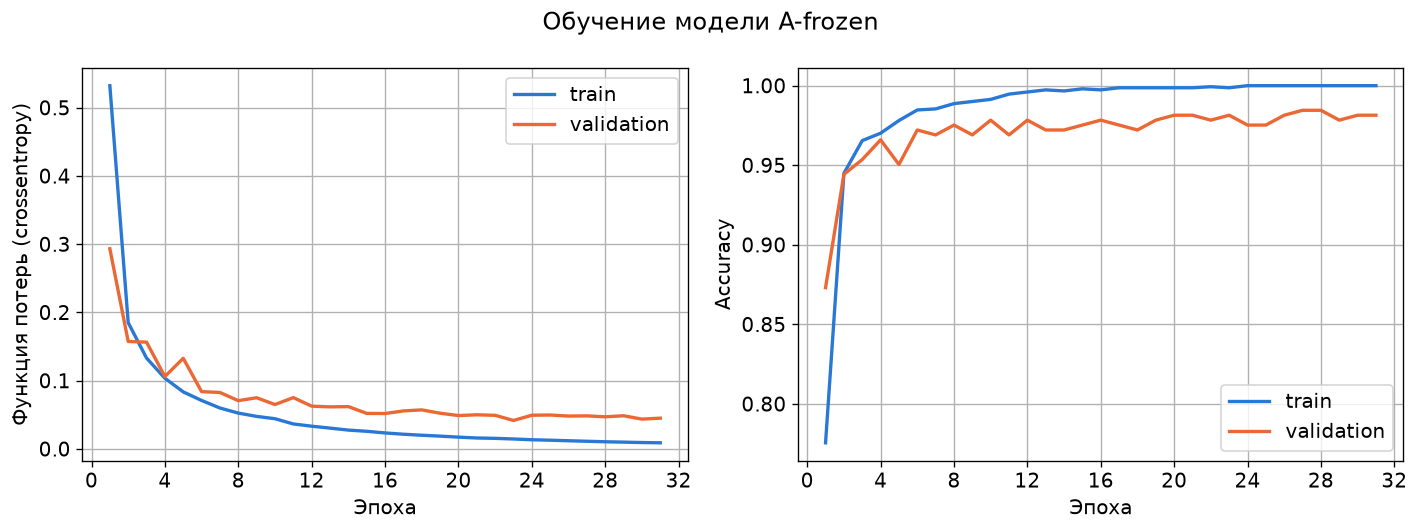

In [15]:
model, base = build_transfer_model(dropout_rate=0.0)
compile_model(model, HEAD_LEARNING_RATE)
describe_architecture(model, base)
train_and_record("A-frozen", model, "A: замороженная основа", 0.0, HEAD_LEARNING_RATE, MAX_EPOCHS_FROZEN, 0)
del model, base
gc.collect()
plot_history("A-frozen", "transfer-a-frozen-history.png")

**Результат:** у модели 2 261 827 параметров, но обучаются только 3843 параметра головы (Dense 1280 x 3 + 3 смещения), основа заморожена. Уже после первой эпохи val accuracy 0,8731: признаки ImageNet подходят для листьев без всякой донастройки. Лучшая эпоха 23 из 31, val loss 0,0417, Balanced Accuracy 0,9744, Macro ROC-AUC 0,9996, обучение 230 с. Train loss 0,0145 ниже val loss: небольшой разрыв, но val loss не растёт, переобучения почти нет.

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value = 6.0 (ReLU6) в 35 слоях
Активации головы: dense_1: softmax
Обучаемых параметров: 3843 из 2261827


A-frozen-dropout: эпох 29, лучшая 21, 196 с, val loss 0.0487, {'Accuracy': 0.9845, 'Balanced Accuracy': 0.9889, 'Macro Precision': 0.9571, 'Macro Recall': 0.9889, 'Macro F1': 0.9718, 'Macro ROC-AUC': 0.9994}


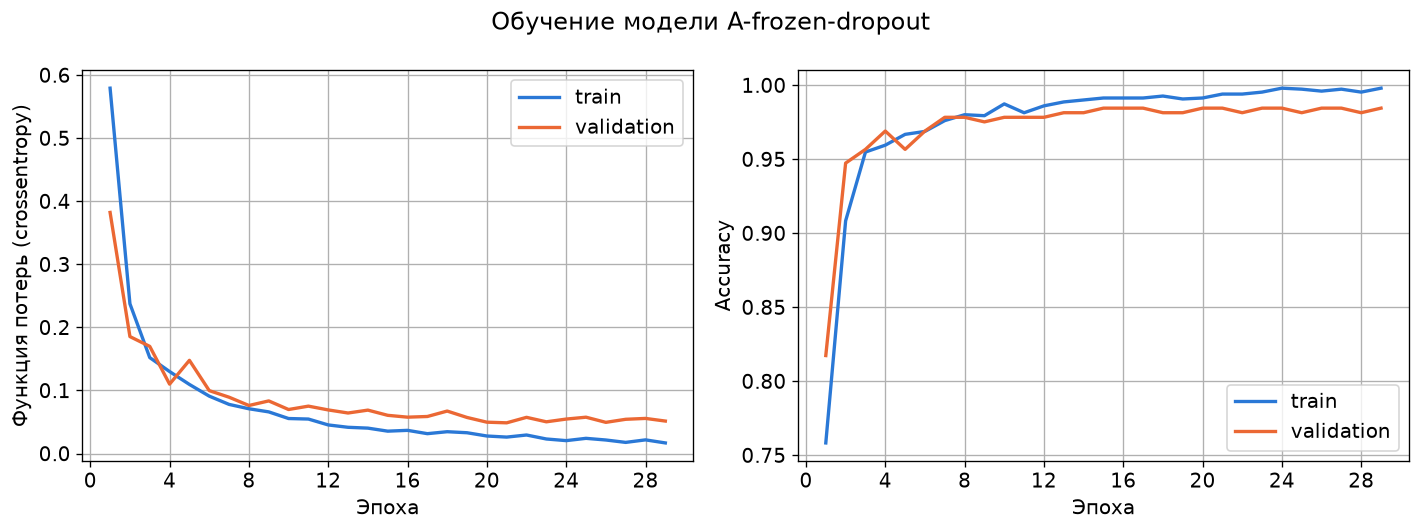

Лучшая модель режима A: A-frozen


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,0.0,0,0.001,3843,31,23,230.0,0.0145,0.0417,0.9987,0.9814,0.9744,0.9687,0.9996
1,A-frozen-dropout,A: замороженная основа,0.2,0,0.001,3843,29,21,195.8,0.0261,0.0487,0.9940,0.9845,0.9889,0.9718,0.9994


In [16]:
model, base = build_transfer_model(dropout_rate=0.2)
compile_model(model, HEAD_LEARNING_RATE)
describe_architecture(model, base)
train_and_record("A-frozen-dropout", model, "A: замороженная основа", 0.2, HEAD_LEARNING_RATE, MAX_EPOCHS_FROZEN, 0)
del model, base
gc.collect()
plot_history("A-frozen-dropout", "transfer-a-frozen-dropout-history.png")

frozen_names = ["A-frozen", "A-frozen-dropout"]
best_frozen_name = select_best(frozen_names)
print("Лучшая модель режима A:", best_frozen_name)
short_table(frozen_names)

**Результат:** голова с Dropout 0,2: val loss 0,0487 против 0,0417 без Dropout, разница 0,007 меньше допуска 0,01. Модели равны по числу обучаемых параметров, поэтому остаётся более простая конфигурация без Dropout, `A-frozen`. Dropout здесь не нужен: у головы всего 3843 параметра, и переобучиться ей трудно.

### 2. Режим B: fine-tuning с частичной разморозкой основы

Начинаем с лучшей модели режима A: голова уже обучена, поэтому большие ошибки случайной головы не разрушат предобученные признаки. Размораживаем последние 30 слоёв основы (блоки 14-16 и последнюю свёртку 1 x 1), нижние слои остаются замороженными: они извлекают общие признаки (границы, текстуры), полезные для любых изображений. После изменения `trainable` модель компилируется заново. Скорость обучения малая: проверяем 10^-5 и 10^-4 из рекомендованного диапазона.

Обучаемых параметров до разморозки: 3843


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 1,514,563 (5.78 MB)

 Non-trainable params: 747,264 (2.85 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value = 6.0 (ReLU6) в 35 слоях
Активации головы: dense_2: softmax
Обучаемых параметров: 1514563 из 2261827
Первый размороженный слой: block_13_project_BN


B-finetune-lr1e-05: эпох 16, лучшая 8, 115 с, val loss 0.0315, {'Accuracy': 0.9907, 'Balanced Accuracy': 0.9933, 'Macro Precision': 0.9711, 'Macro Recall': 0.9933, 'Macro F1': 0.9816, 'Macro ROC-AUC': 0.9999}


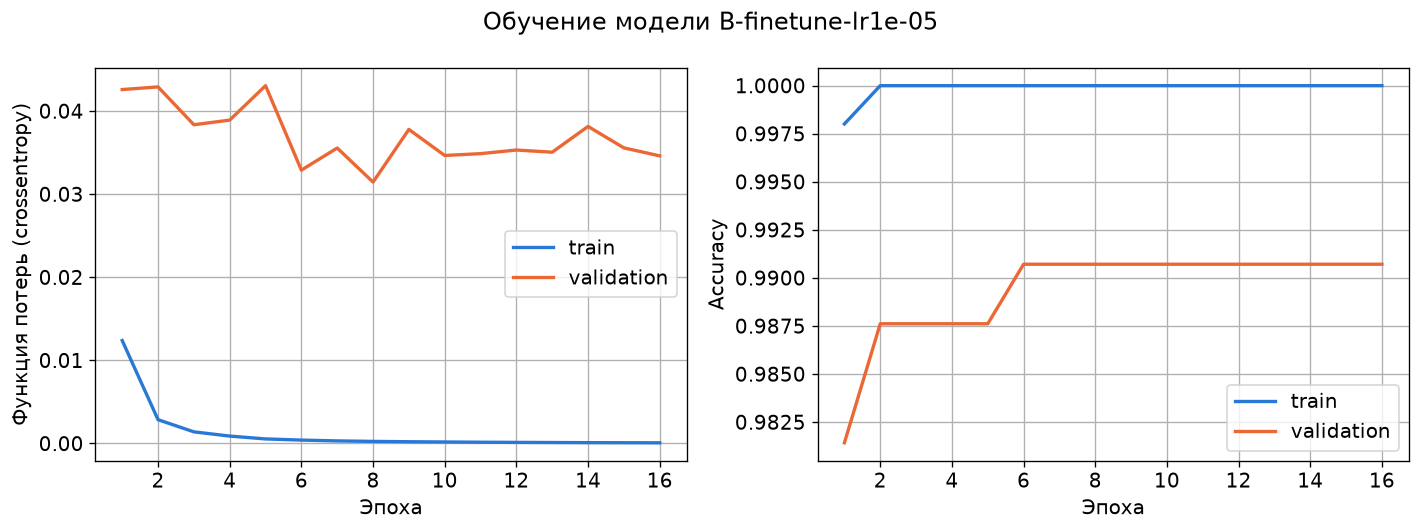

Обучаемых параметров до разморозки: 3843


B-finetune-lr0.0001: эпох 14, лучшая 6, 100 с, val loss 0.0078, {'Accuracy': 0.9969, 'Balanced Accuracy': 0.9978, 'Macro Precision': 0.9861, 'Macro Recall': 0.9978, 'Macro F1': 0.9918, 'Macro ROC-AUC': 1.0}


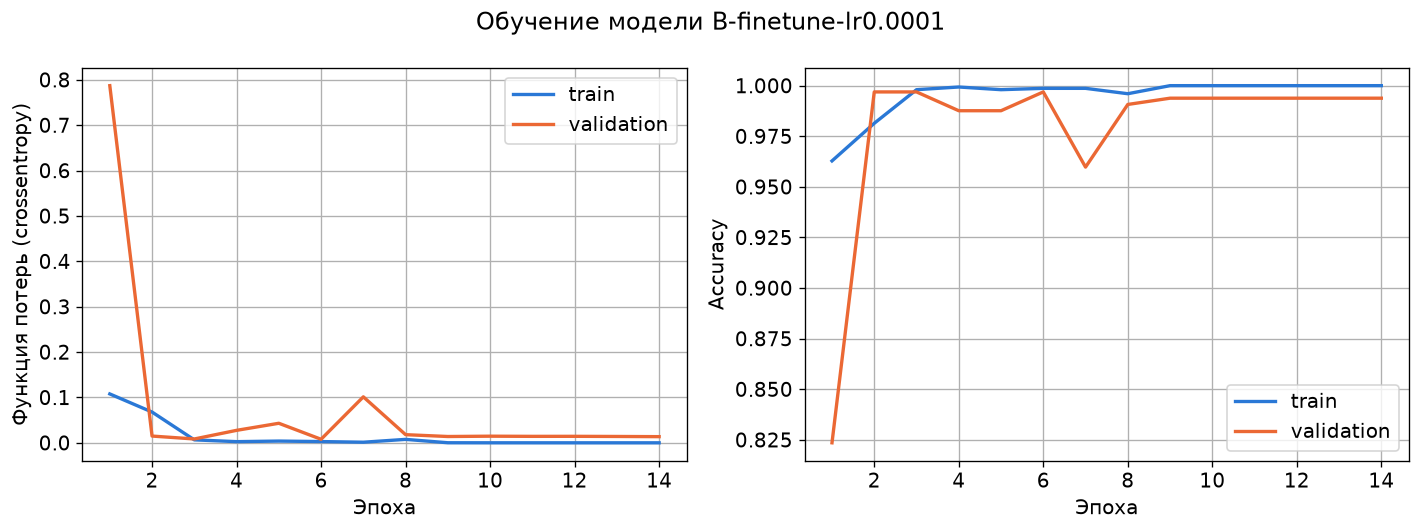

Лучшая модель режима B: B-finetune-lr0.0001


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,B-finetune-lr1e-05,B: fine-tuning,0.0,30,0.00001,1514563,16,8,114.5,0.0003,0.0315,1.0000,0.9907,0.9933,0.9816,0.9999
1,B-finetune-lr0.0001,B: fine-tuning,0.0,30,0.00010,1514563,14,6,100.2,0.0028,0.0078,0.9987,0.9969,0.9978,0.9918,1.0000


In [17]:
frozen_dropout = model_settings[best_frozen_name]["dropout_rate"]
fine_names = []
for learning_rate in FINE_TUNE_LEARNING_RATES:
    fine_name = f"B-finetune-lr{learning_rate:g}"
    model, base = build_transfer_model(frozen_dropout)
    # Начальные веса - лучшие веса режима A
    model.load_weights(model_file(best_frozen_name))
    print("Обучаемых параметров до разморозки:", count_trainable(model))
    unfreeze_top(base, UNFROZEN_LAYERS)
    # После изменения trainable обязательно компилируем заново
    compile_model(model, learning_rate)
    if learning_rate == FINE_TUNE_LEARNING_RATES[0]:
        describe_architecture(model, base)
        print("Первый размороженный слой:", base.layers[-UNFROZEN_LAYERS].name)
    train_and_record(fine_name, model, "B: fine-tuning", frozen_dropout, learning_rate, MAX_EPOCHS_FINE, UNFROZEN_LAYERS)
    fine_names.append(fine_name)
    del model, base
    gc.collect()
    plot_history(fine_name, f"transfer-{fine_name.lower()}-history.png")

best_fine_name = select_best(fine_names)
print("Лучшая модель режима B:", best_fine_name)
short_table(fine_names)

**Результат:** после разморозки 30 слоёв (с `block_13_project_BN`, сами слои BatchNormalization заморожены) обучаемых параметров 1 514 563 вместо 3843. С шагом 10^-4: лучшая эпоха 6 из 14, val loss 0,0078, Balanced Accuracy 0,9978, 1 ошибка на validation. С шагом 10^-5: эпоха 8 из 16, val loss 0,0315. Шаг 10^-4 в первую эпоху резко сдвинул признаки (val loss подскочил до 0,7871 и val accuracy упала до 0,8235), но потом сеть восстановилась и стала лучше: это и есть риск слишком агрессивного обновления, о котором говорит задание, а Early Stopping с восстановлением лучших весов его страхует. Шаг 10^-5 изменяет основу плавно, без такого скачка, но за 16 эпох улучшил val loss меньше. Train loss режима B падает почти до нуля (0,0028 и 0,0003): 1,5 млн параметров легко запоминают 1506 снимков, поэтому обучение остановилось быстро.

### 3. Сравнение режимов на validation и матрицы ошибок

Сравниваем лучшие модели двух режимов. Матрицы ошибок показывают, какие классы путаются и исправляет ли fine-tuning эти ошибки.

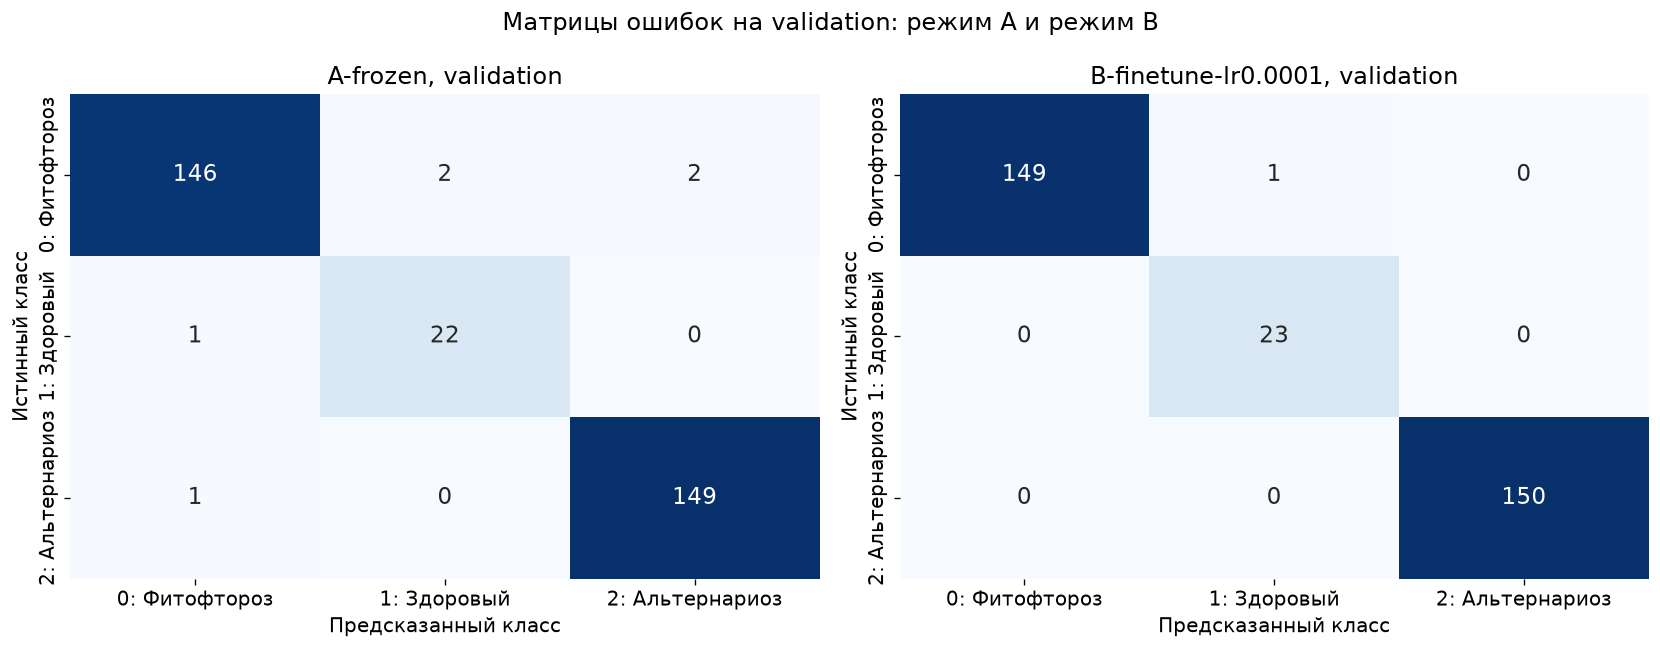

A-frozen


,Precision,Recall,F1,ROC-AUC,Объектов
0: Фитофтороз,0.9865,0.9733,0.9799,0.9994,150
1: Здоровый,0.9167,0.9565,0.9362,0.9997,23
2: Альтернариоз,0.9868,0.9933,0.9900,0.9998,150
macro avg,0.9633,0.9744,0.9687,0.9996,323


B-finetune-lr0.0001


,Precision,Recall,F1,ROC-AUC,Объектов
0: Фитофтороз,1.0000,0.9933,0.9967,1.0,150
1: Здоровый,0.9583,1.0000,0.9787,1.0,23
2: Альтернариоз,1.0000,1.0000,1.0000,1.0,150
macro avg,0.9861,0.9978,0.9918,1.0,323


Итоговая модель по validation: B-finetune-lr0.0001


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,0.0,0,0.0010,3843,31,23,230.0,0.0145,0.0417,0.9987,0.9814,0.9744,0.9687,0.9996
1,B-finetune-lr0.0001,B: fine-tuning,0.0,30,0.0001,1514563,14,6,100.2,0.0028,0.0078,0.9987,0.9969,0.9978,0.9918,1.0000


In [18]:
compare_names = [best_frozen_name, best_fine_name]
figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))
val_tables = {}
for axis, model_name in zip(axes, compare_names):
    model = load_trained(model_name)
    probabilities = model.predict(X_val, batch_size=64, verbose=0)
    plot_confusion(y_val, probabilities, f"{model_name}, validation", axis)
    val_tables[model_name] = per_class_table(y_val, probabilities)
    del model
    gc.collect()
figure.suptitle("Матрицы ошибок на validation: режим A и режим B")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "transfer-val-confusion.png")
plt.show()

for model_name, table in val_tables.items():
    print(model_name)
    display(table)

final_name = select_best(compare_names)
print("Итоговая модель по validation:", final_name)
short_table(compare_names)

**Результат:** на validation `A-frozen` ошибается 6 раз: 2 листа с фитофторозом названы здоровыми, 2 - альтернариозом, 1 здоровый и 1 альтернариоз названы фитофторозом. После fine-tuning (`B-finetune-lr0.0001`) осталась 1 ошибка: фитофтороз назван здоровым. Путаются фитофтороз с двумя другими классами: у фитофтороза пятна бывают маленькими и только у края листа (тогда лист похож на здоровый), а бурые пятна похожи на альтернариоз. Дообучение верхних слоёв подстроило признаки под эти пятна. Val loss 0,0078 против 0,0417 - разница больше допуска, итоговая модель - `B-finetune-lr0.0001`. Лучшие модели обоих режимов сохранены в `models/transfer-frozen-best.keras` и `models/transfer-finetune-best.keras`.

Сохраняем лучшую модель каждого режима целиком (архитектура, веса, оптимизатор) и полную таблицу экспериментов с параметрами.

In [19]:
for model_name, file_name in [(best_frozen_name, "transfer-frozen-best.keras"), (best_fine_name, "transfer-finetune-best.keras")]:
    model = load_trained(model_name)
    model.save(MODELS_DIR / file_name)
    del model
pd.Series({"frozen_best": best_frozen_name, "finetune_best": best_fine_name, "final": final_name,
           "input": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3 RGB, mobilenet_v2.preprocess_input"}).to_csv(
    RESULTS_DIR / "transfer-best-models.csv", header=["value"], encoding="utf-8")

all_experiments = experiments_table()
all_experiments.to_csv(RESULTS_DIR / "transfer-experiments.csv", index=False, encoding="utf-8")
pd.set_option("display.max_columns", None, "display.width", 250)
all_experiments

,Модель,Режим,Вход,Архитектура,Разморожено слоёв основы,Dropout,Оптимизатор,lr,Batch,Обучаемых параметров,Всего параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro Precision,val Macro Recall,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,0,0.0,adam,0.00100,32,3843,2261827,40,31,23,230.0,0.0145,0.0417,0.9987,0.9814,0.9744,0.9633,0.9744,0.9687,0.9996
1,A-frozen-dropout,A: замороженная основа,224x224x3,MobileNetV2 (ImageNet) + GAP + Dropout 0.2 + D...,0,0.2,adam,0.00100,32,3843,2261827,40,29,21,195.8,0.0261,0.0487,0.9940,0.9845,0.9889,0.9571,0.9889,0.9718,0.9994
2,B-finetune-lr1e-05,B: fine-tuning,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,30,0.0,adam,0.00001,32,1514563,2261827,30,16,8,114.5,0.0003,0.0315,1.0000,0.9907,0.9933,0.9711,0.9933,0.9816,0.9999
3,B-finetune-lr0.0001,B: fine-tuning,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,30,0.0,adam,0.00010,32,1514563,2261827,30,14,6,100.2,0.0028,0.0078,0.9987,0.9969,0.9978,0.9861,0.9978,0.9918,1.0000


## Итоговая оценка на тестовой выборке

Выбор сделан по validation. Тестовая выборка используется один раз: все модели оцениваются на ней как отчёт, без изменений после этого.

In [20]:
test_rows = [{"Модель": "Dummy", **evaluate_multiclass(y_test, dummy.predict_proba(np.zeros((len(y_test), 1))))}]
test_probabilities = {}
for model_name in model_settings:
    model = load_trained(model_name)
    test_probabilities[model_name] = model.predict(X_test, batch_size=64, verbose=0)
    test_rows.append({"Модель": model_name, **evaluate_multiclass(y_test, test_probabilities[model_name])})
    del model
    gc.collect()
test_table = pd.DataFrame(test_rows)
test_table.to_csv(RESULTS_DIR / "transfer-test-metrics.csv", index=False, encoding="utf-8")
test_table

,Модель,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Dummy,0.4644,0.3333,0.1548,0.3333,0.2114,0.5000
1,A-frozen,0.9876,0.9911,0.9689,0.9911,0.9794,0.9998
2,A-frozen-dropout,0.9814,0.9867,0.9461,0.9867,0.9644,0.9998
3,B-finetune-lr1e-05,0.9938,0.9956,0.9839,0.9956,0.9896,1.0000
4,B-finetune-lr0.0001,0.9876,0.9911,0.9506,0.9911,0.9688,0.9998


**Результат:** все модели переноса обучения на test намного лучше `Dummy` (Balanced Accuracy 0,3333, Macro ROC-AUC 0,5) и выше ориентира 0,80. Итоговая `B-finetune-lr0.0001`: Accuracy 0,9876, Balanced Accuracy 0,9911, Macro F1 0,9688, Macro ROC-AUC 0,9998. `A-frozen` на test имеет такую же Accuracy 0,9876 и Balanced Accuracy 0,9911 и даже чуть выше Macro F1 (0,9794). Лучшая на test - `B-finetune-lr1e-05` (2 ошибки, Macro F1 0,9896). Но различие - 2 снимка из 323, а выбор сделан по validation и после теста не меняется: на validation fine-tuning с шагом 10^-4 был лучшим с запасом.

### Метрики по классам и матрицы ошибок лучших моделей двух режимов на test

A-frozen


,Precision,Recall,F1,ROC-AUC,Объектов
0: Фитофтороз,0.9867,0.9867,0.9867,0.9995,150
1: Здоровый,0.9200,1.0000,0.9583,0.9999,23
2: Альтернариоз,1.0000,0.9867,0.9933,0.9999,150
macro avg,0.9689,0.9911,0.9794,0.9998,323


B-finetune-lr0.0001


,Precision,Recall,F1,ROC-AUC,Объектов
0: Фитофтороз,1.0000,0.9733,0.9865,0.9997,150
1: Здоровый,0.8519,1.0000,0.9200,0.9999,23
2: Альтернариоз,1.0000,1.0000,1.0000,1.0000,150
macro avg,0.9506,0.9911,0.9688,0.9998,323


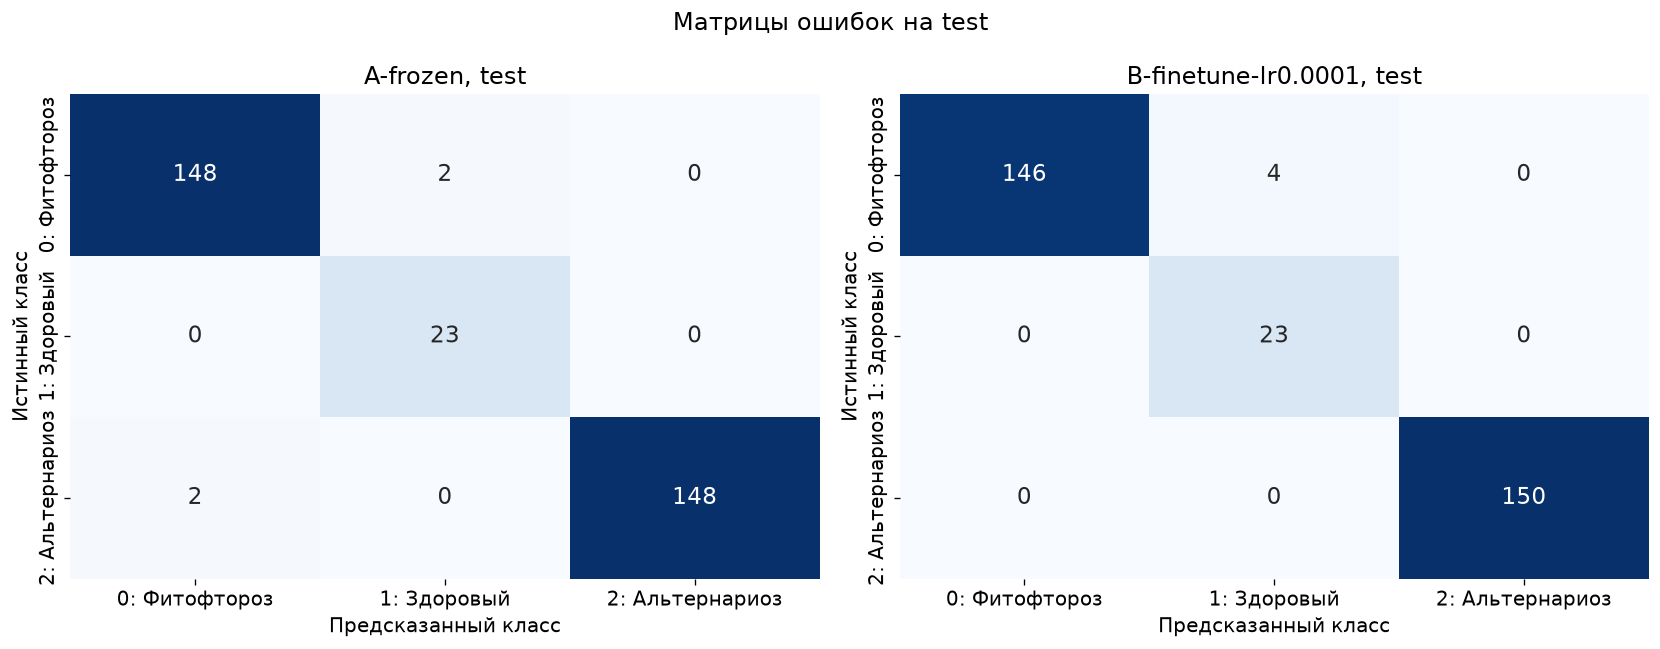

In [21]:
per_class_rows = []
figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for axis, model_name in zip(axes, compare_names):
    plot_confusion(y_test, test_probabilities[model_name], f"{model_name}, test", axis)
    table = per_class_table(y_test, test_probabilities[model_name])
    print(model_name)
    display(table)
    per_class_rows.append(table.assign(Модель=model_name).reset_index(names="Класс"))
figure.suptitle("Матрицы ошибок на test")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "transfer-test-confusion.png")
plt.show()
pd.concat(per_class_rows).to_csv(RESULTS_DIR / "transfer-test-per-class.csv", index=False, encoding="utf-8")

**Результат:** итоговая модель на test: альтернариоз распознан без ошибок (Precision, Recall, F1 = 1,0), здоровые листья найдены все (Recall 1,0), но 4 листа с фитофторозом названы здоровыми, поэтому Recall фитофтороза 0,9733, а Precision здоровых 0,8519. Macro-average: Precision 0,9506, Recall 0,9911, F1 0,9688. `A-frozen` ошибается тоже 4 раза, но иначе: 2 фитофтороза названы здоровыми, 2 альтернариоза - фитофторозом (Precision здоровых 0,92, F1 альтернариоза 0,9933). Fine-tuning убрал путаницу двух болезней, но на test не убрал главную опасную ошибку - фитофтороз, принятый за здоровый лист.

### Итоговая модель: кривые обучения с линией test и ROC-кривые One-vs-Rest

B-finetune-lr0.0001: test loss 0.0499, test accuracy 0.9876


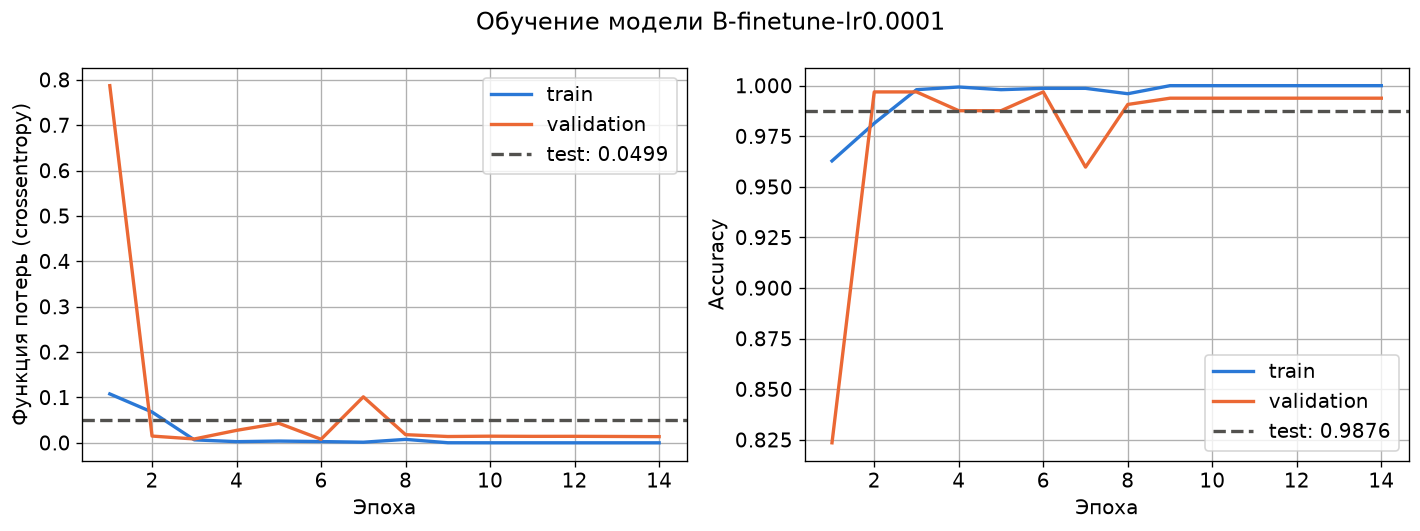

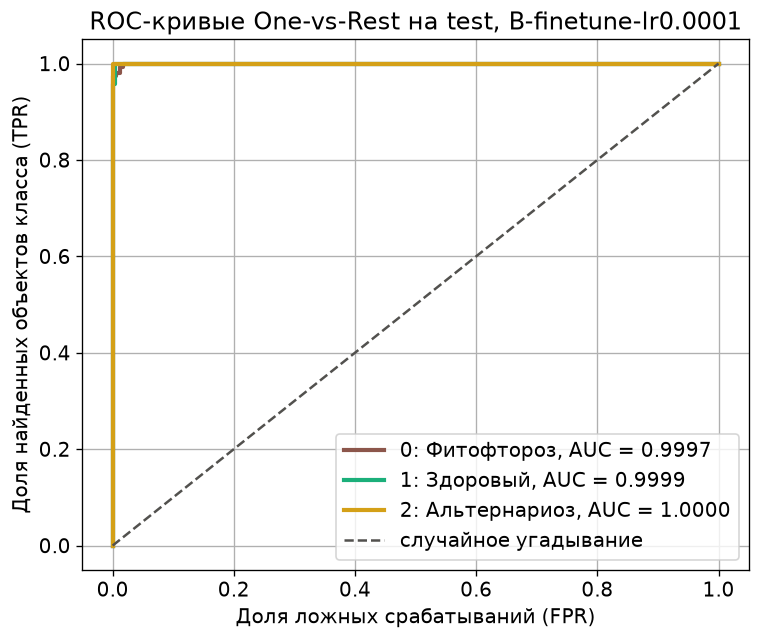

Ошибок на test: 4


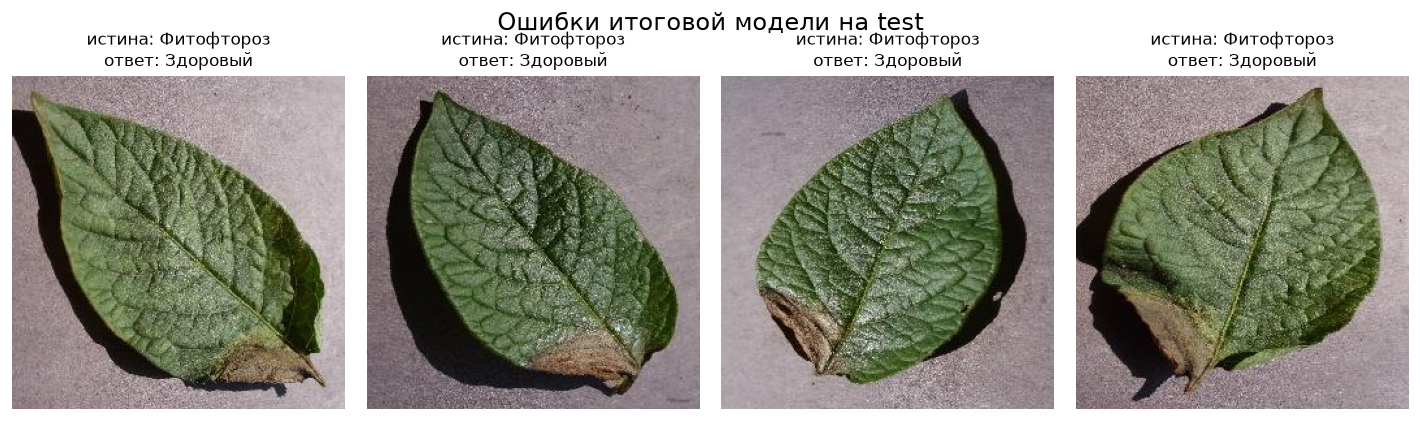

In [22]:
final_model = load_trained(final_name)
compile_model(final_model, HEAD_LEARNING_RATE)
final_test_loss, final_test_accuracy = final_model.evaluate(X_test, y_test, batch_size=64, verbose=0)
print(f"{final_name}: test loss {final_test_loss:.4f}, test accuracy {final_test_accuracy:.4f}")
plot_history(final_name, "transfer-best-history.png",
             test_values={"loss": final_test_loss, "accuracy": final_test_accuracy})

figure, axis = plt.subplots(figsize=(6.5, 5.5))
for label in ALL_LABELS:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test == label, test_probabilities[final_name][:, label])
    auc = roc_auc_score(y_test == label, test_probabilities[final_name][:, label])
    axis.plot(false_positive_rate, true_positive_rate, linewidth=2.5, color=CLASS_COLORS[label],
              label=f"{label}: {CLASS_NAMES[label]}, AUC = {auc:.4f}")
axis.plot([0, 1], [0, 1], color=TEST_COLOR, linestyle="--", label="случайное угадывание")
axis.set_xlabel("Доля ложных срабатываний (FPR)")
axis.set_ylabel("Доля найденных объектов класса (TPR)")
axis.set_title(f"ROC-кривые One-vs-Rest на test, {final_name}")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "transfer-best-roc.png")
plt.show()

# Ошибочные снимки теста итоговой модели
final_predicted = test_probabilities[final_name].argmax(axis=1)
error_indices = np.flatnonzero(final_predicted != y_test)
print("Ошибок на test:", len(error_indices))
if len(error_indices) > 0:
    test_files = files[files["split"] == "test"]["file"].tolist()
    shown = error_indices[:8]
    figure, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.6), squeeze=False)
    for axis, index in zip(axes[0], shown):
        with Image.open(IMAGE_DIR / test_files[index]) as image:
            axis.imshow(image)
        axis.set_title(f"истина: {CLASS_NAMES[y_test[index]]}\nответ: {CLASS_NAMES[final_predicted[index]]}", fontsize=10)
        axis.axis("off")
    figure.suptitle("Ошибки итоговой модели на test")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / "transfer-best-errors.png")
    plt.show()

**Результат:** test loss 0,0499, test accuracy 0,9876. Кривые режима B начинаются с высокой точности (обучение продолжается с весов режима A), после скачка на первой эпохе val loss снижается до 0,0078 на 6-й эпохе. Затем train loss стремится к нулю, а val loss перестаёт улучшаться, и Early Stopping останавливает обучение. ROC-AUC по классам на test 0,9997-1,0: модель почти идеально ранжирует снимки, ошибки возникают только при выборе класса с наибольшей вероятностью. Все 4 ошибки - листья с фитофторозом, у которых поражён только маленький сухой участок на кончике или у черешка, а остальная часть листа зелёная и чистая. Для такой сети это почти здоровый лист: в обучающей выборке у большинства листьев с фитофторозом пятна крупнее.

## Вывод

1. **Данные.** Три класса варианта 7: фитофтороз 1000, здоровые 152, альтернариоз 1000 снимков; файлы целы, метки верны, снимки одного листа в одной выборке. Здоровый класс редкий (7%), поэтому использованы веса классов (4,7358 для здоровых, 0,7171 для остальных).
2. **Трёхклассовый классификатор на основе ImageNet.** MobileNetV2 с головой GlobalAveragePooling2D + Dense(3, softmax), входы через `preprocess_input`. Даже с замороженной основой (режим A, обучаются 3843 параметра) получено Balanced Accuracy 0,9744 на validation и 0,9911 на test: признаки, выученные на 1,2 млн изображений ImageNet, хорошо описывают пятна на листьях. `Dummy`: 0,3333.
3. **Сравнение режимов.** Fine-tuning верхних 30 слоёв (режим B, 1,5 млн обучаемых параметров) снизил val loss с 0,0417 до 0,0078 и число ошибок на validation с 6 до 1, поэтому по validation эффективнее режим B. Шаг 10^-4 дал лучший результат, чем 10^-5, но в первую эпоху резко сдвинул признаки: малый шаг и контроль val loss при fine-tuning действительно нужны. Dropout в голове не понадобился.
4. **Тест.** Итоговая `B-finetune-lr0.0001`: Accuracy 0,9876, Balanced Accuracy 0,9911, Macro F1 0,9688, Macro ROC-AUC 0,9998. На test режимы A и B делают одинаково по 4 ошибки: fine-tuning убрал путаницу между двумя болезнями, но 4 листа с фитофторозом в виде маленького поражения на кончике листа модель приняла за здоровые. Разница режимов на test (единицы снимков) меньше, чем на validation, потому что обе модели уже близки к пределу на этих чистых лабораторных снимках.
5. **Почему так.** Снимки сделаны в одинаковых условиях на однородном фоне, а болезни хорошо видны по цвету и форме пятен, поэтому предобученная сеть почти не ошибается. Оставшиеся ошибки - ранние стадии фитофтороза с маленьким поражением, которых в обучающей выборке мало; их можно уменьшить, добавив такие примеры или снизив порог для класса "здоровый" по validation.